In [1]:
from astropy.config import generate_config
generate_config(pkgname='synphot')
from astropy import units as u
from synphot import units, SourceSpectrum
from synphot.models import BlackBodyNorm1D, GaussianFlux1D

import matplotlib.pyplot as plt,  matplotlib.gridspec as gridspec

import numpy as np
import astropy.constants as const

from astropy.constants import Constant
# Fetch one filter's transmission curve
from astroquery.svo_fps import SvoFps
import numpy as np
from synphot import SpectralElement
from synphot.models import Empirical1D

import Syn_Spec_toolkits as SSt
%load_ext autoreload
%autoreload 2



In [2]:
T_eff = 5000
wave        = np.logspace(2, 6.5, int(1e5)) * u.AA         
wave_um     = wave.to(u.um).value

In [11]:
paths, temps        = SSt.Find_available_models()
T_idx               = np.argmin(np.abs(T_eff-temps))
model_path_to_use   = paths[T_idx]

print(model_path_to_use)
sp_star             = SourceSpectrum.from_file(str(model_path_to_use), wave_col='WAVELENGTH', flux_col='g30')



bessell_for_luka/cm05_05000.fits


In [22]:
A_ref           = (np.pi * const.R_sun**2).to(u.m**2)
R_in, R_out     = [5, 20]* const.R_sun #[0.1, 0.2] * u.au
A_disk          = (np.pi * (R_out**2 - R_in**2)).to(u.m**2)
disc_scale      = (A_disk/A_ref)
T_disc          = 1000 * u.K

# F ∝ d^-2 -> F_disc = F_bb (d_bb/Rsun)^2 where d_bessel = 1 kpc
# blackbody is per definition at Rsun at 1 kpc
scale           = ((const.kpc/const.R_sun).value)**(2)
bb_disc         = SourceSpectrum(BlackBodyNorm1D, temperature= T_disc) * scale 
sp_disc         = 0 *bb_disc * disc_scale
sp_tot          = sp_star + sp_disc

line_emission_pa = SSt.Obtain_line_Weq( lam0 = SSt.wave_pa_alpha.to(u.AA),
                                W_eq = 8 * u.AA,
                                continuum =  sp_tot,
                               )

line_emission_br = SSt.Obtain_line_Weq(  lam0 = SSt.wave_br_alpha.to(u.AA),
                                W_eq = 8 * u.AA,
                                continuum =  sp_tot,
                               )

sp_tot += line_emission_pa 
sp_tot += line_emission_br


In [23]:
0.008613346755872442 

0.008932759782595853


0.008932759782595853

In [24]:
mag_continuum           = SSt.Compute_model_abs_MAG(    sp      = sp_star + sp_disc ,
                                                        T_eff   = T_eff,
                                                        filter  = 'F187N')
mag_continuum_and_line  = SSt.Compute_model_abs_MAG(    sp      = sp_tot ,
                                                        T_eff   = T_eff,
                                                        filter  = 'F187N')

print(( mag_continuum - mag_continuum_and_line ))

0.03403659497631395 mag


In [25]:
d          = 200000 * u.lyr
dist_scale = ((1*u.Rsun/d)).decompose().value**(2)

print(sp_tot(1*u.um,flux_unit='mJy') *dist_scale )
M = SSt.Compute_model_abs_MAG(sp=sp_tot, T_eff=T_eff, filter='F115W')   # absolute (10 pc)
m = M + 5*np.log10((d/(10*u.pc)).decompose().value) * units.VEGAMAG     # apparent at d

0.0009762990735949401 mJy


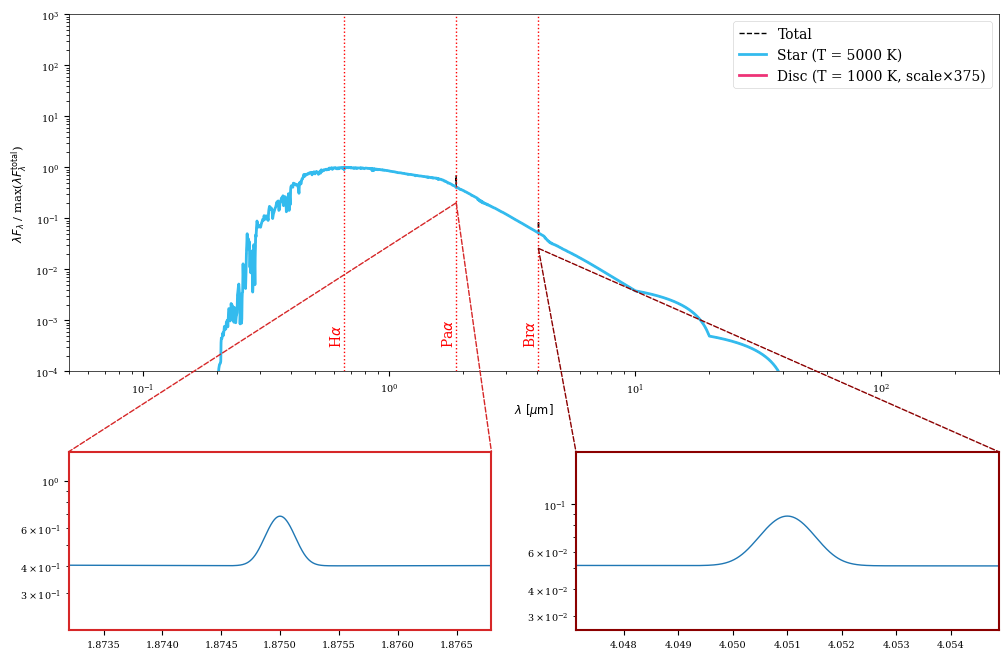

In [16]:

SSt.plot_spectrum_modeled_source(sp_tot    = sp_tot  ,
                                sp_star    = sp_star ,
                                sp_disc    = sp_disc ,
                                disc_scale = disc_scale,
                                T_eff      = T_eff,
                                T_disc     = T_disc)


In [10]:


    
import numpy as np
from IPython.display import display, Math

for lam, name in [(0.6563, r'H\alpha'), (1.875, r'Pa\alpha'), (4.051, r'Br\alpha')]:
    value = np.round(sp_star(lam*u.um, flux_unit='flam') / sp_star(0.6563*u.um, flux_unit='flam'), 3)

    ratio1 = rf"F_{{*}}({name}) / F_{{*}}(H\alpha) = \text{{ {value} }}"
    display(Math(ratio1))
print()

for lam, name in [(0.6563, r'H\alpha'), (1.875, r'Pa\alpha'), (4.051, r'Br\alpha')]:
    value = np.round(bb_disc(lam*u.um, flux_unit='flam') / sp_star(lam*u.um, flux_unit='flam'), 3)
    ratio3 = rf"$F_{{disc}}({name}) / F_{{*}}({name}) = \text{{ {value} }}$"
    display(Math(ratio3))
    



<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>